Dino v1

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

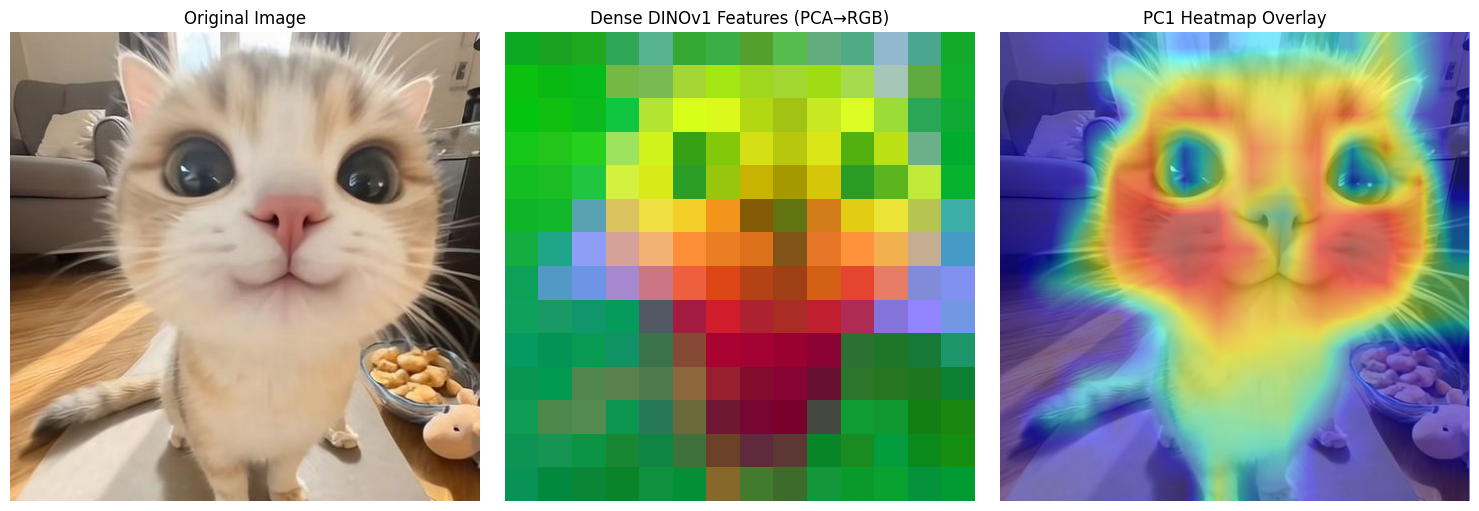

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, AutoImageProcessor
from PIL import Image

# --- 1. Extract dense features with DINOv1 ---
model_name = "facebook/dino-vitb16"   # or "facebook/dino-vits16", "facebook/dino-vitb8", "facebook/dino-vitl16"
model = AutoModel.from_pretrained(model_name).eval()
processor = AutoImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

last_hidden = outputs.last_hidden_state   # [B, 1 + N, D] — CLS at index 0
patch_tokens = last_hidden[:, 1:, :]      # [1, N, D] — drop CLS token
B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)                 # e.g. 14 for vitb16 (224/16=14)

patch_tokens_np = patch_tokens[0].numpy() # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense DINOv1 Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("dino_v1_dense_features.png", dpi=150)
plt.show()

Dino v2

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

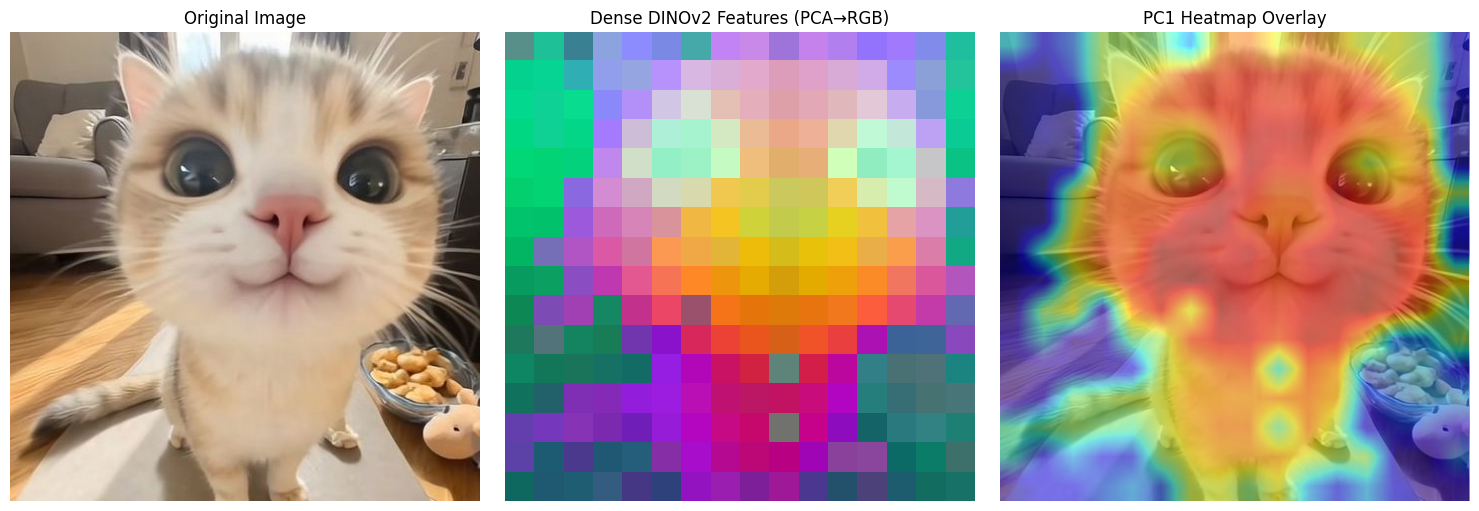

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, AutoImageProcessor
from PIL import Image

# --- 1. Extract dense features with DINOv2 ---
model_name = "facebook/dinov2-base"          # or "facebook/dinov2-large", "facebook/dinov2-giant"
model = AutoModel.from_pretrained(model_name).eval()
processor = AutoImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    outputs = model(
        pixel_values=inputs["pixel_values"],
        output_hidden_states=True,
    )

last_hidden = outputs.last_hidden_state      # DINOv2: [B, N+1, D] — includes CLS token at index 0
patch_tokens = last_hidden[:, 1:, :]         # [1, N, D] — drop CLS token
B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)                    # e.g. 14 for base, 16 for large (depending on patch size)

patch_tokens_np = patch_tokens[0].numpy()    # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense DINOv2 Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("dino_dense_features.png", dpi=150)
plt.show()

Dino v3

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

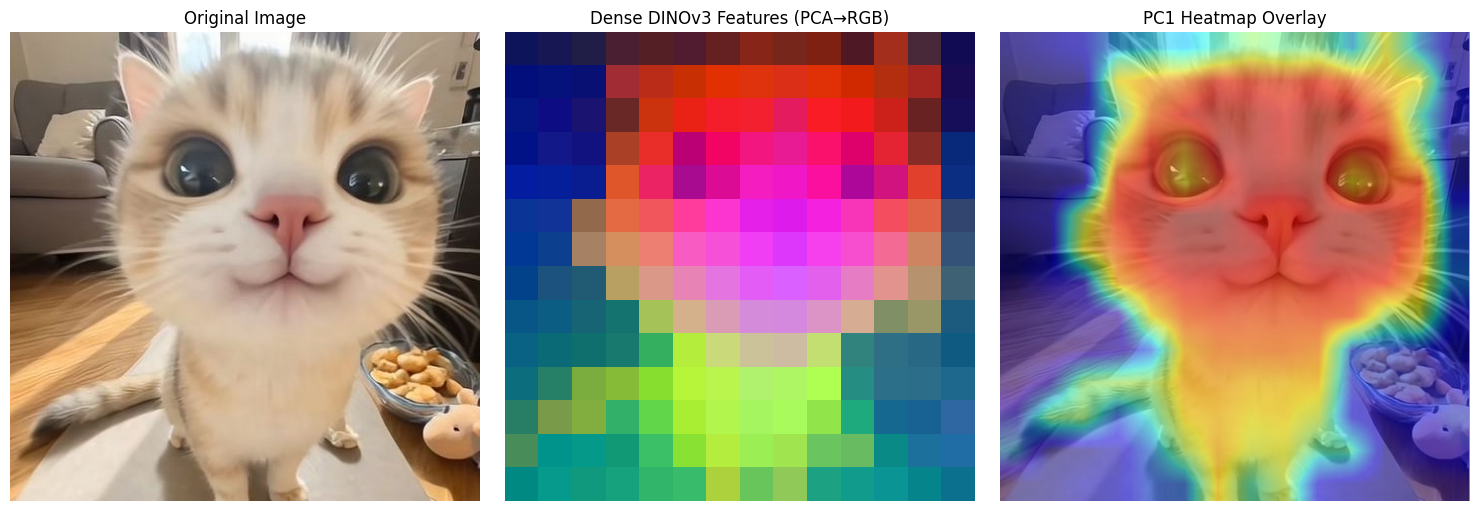

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, AutoImageProcessor
from PIL import Image

# --- 1. Extract dense features with DINOv3 ---
model_name = "facebook/dinov3-vitb16-pretrain-lvd1689m"  # or vits16, vitl16, vit7b16, etc.
model = AutoModel.from_pretrained(model_name).eval()
processor = AutoImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

last_hidden = outputs.last_hidden_state  # [B, 1 + num_registers + N, D]

# DINOv3 has register tokens between CLS and patches — skip them!
num_registers = model.config.num_register_tokens  # typically 4
patch_tokens = last_hidden[:, 1 + num_registers:, :]   # [1, N, D]

B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)                              # e.g. 14 for 224×224 input

patch_tokens_np = patch_tokens[0].numpy()              # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)      # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense DINOv3 Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("dinov3_dense_features.png", dpi=150)
plt.show()